# Carrier Mobility from AMSET

#### Pre-requisites:
* Everything the figure of merit tutorial (`fom_tutorial.ipynb`) needs
* An [AMSET](https://hackingmaterials.lbl.gov/amset/) calculation on the same structure

$\Gamma_{\mathrm{PV}}$ takes one carrier mobility $\mu$ next to the doping density $n$, and the two are not independent: ionized impurities scatter more as $n$ rises, and free carriers screen polar-optical scattering. The figure of merit tutorial sweeps $n$ at a fixed $\mu$. Here $\mu(n)$ comes from AMSET instead, so every doping density uses its own mobility.

Two definitions line up, which is what makes this possible:

* AMSET's `doping` is the net free-carrier concentration $|n - p|$, the same quantity as Crovetto's $n = |N_\mathrm{D} - N_\mathrm{A}|$ (equation 3). It is not a count of charged defects.
* AMSET's mobility is the conductivity (drift) mobility of the majority carrier at that doping, the $\mu = q\tau_\mathrm{s}/M$ of Crovetto's equation 5.

Only the AMSET transport file is read, so AMSET itself does not need to be installed here.

## Running AMSET for solphin

A few AMSET settings decide whether its output is usable here:

* `doping`: both signs (negative is n-type, positive p-type), so both carriers' mobilities exist, and spanning the $\Gamma_{\mathrm{PV}}$ range $10^{10}$ - $10^{18}$ cm⁻³. Extra doping values only cost post-processing.
* `temperatures`: must include the cell temperature.
* `separate_mobility: true`: the per-mechanism mobilities are what solphin's checks use.
* `write_input: true`: keeps `compensation_factor` and `defect_charge` next to the results, since the transport file does not record them.

The file used here is a Cu₂GeS₃ run on the same structure as the other tutorials, with HSE06 bands. Its settings are in `tests/data/Cu2GeS3/AMSET/settings.yaml`. Two of its inputs are estimates rather than calculations (the ionic dielectric contribution and the polar-optical phonon frequency), so treat the numbers as an illustration.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import solphin.band_structure as band_structure
import solphin.db_fom as db_fom
import solphin.dos as dos
import solphin.final_results as final_results
import solphin.optics as optics
import solphin.spectral as spectral
import solphin.transport as transport

# After the solphin imports: sumo, which solphin uses, switches matplotlib to its
# non-interactive Agg backend on import.
%matplotlib inline

amset_file = "../tests/data/Cu2GeS3/AMSET/transport_49x49x43.json"

## What the file holds

In [2]:
data = transport.load_amset_transport(amset_file)

print("Carriers:   ", data.carriers)
print("Mechanisms: ", data.mechanisms)
print("Temperatures:", data.temperatures, "K")

Carriers:    ('electrons', 'holes')
Mechanisms:  ('overall', 'ADP', 'IMP', 'POP')
Temperatures: [300.] K


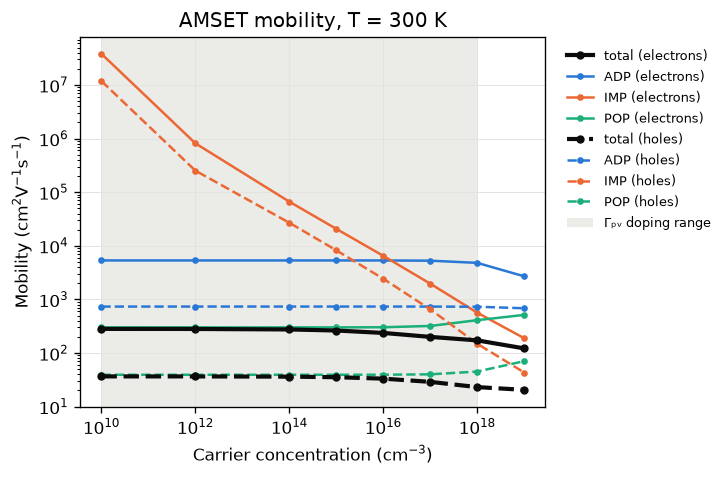

In [3]:
transport.plot_mobility(data, temperature=300)
plt.show()

Electrons are solid lines, holes dashed; the shaded band is the doping range $\Gamma_{\mathrm{PV}}$ was fitted over. In Cu₂GeS₃ both carriers are limited by polar-optical phonons (POP) up to about $10^{17}$ cm⁻³, after which ionized impurities (IMP) take over. Free-carrier screening makes the POP-limited mobility rise at high doping. Holes are about eight times slower than electrons.

## Choosing the mobility for the figure of merit

`select_mobility` turns the file into a function $\mu(n)$ and prints what it is using and why:

In [4]:
import warnings

# Each check is both printed in the summary and raised as a Python warning (for
# scripts and tests). In a notebook that shows everything twice, so the
# warnings from this file are silenced here; the summary keeps them all.
warnings.filterwarnings("ignore", message="transport_49x49x43.json")

mu_limiting = transport.select_mobility(amset_file, temperature=300)

AMSET transport: transport_49x49x43.json  (T = 300 K)
Mobility used for Γₚᵥ: limiting carrier: the lower of the electron and hole mobilities
Scattering: 'overall' (total)
Tensor: isotropic average (trace / 3)
Doping grid: 1e+10 - 1e+19 cm⁻³
  - ⚠ Ionized impurities exceed 10% of electron scattering from 1e+17 cm⁻³ (10.2% there). The compensation_factor and defect_charge AMSET used (not stored in the transport file) matter from that doping on.
  - ⚠ Ionized impurities exceed 10% of hole scattering from 1e+18 cm⁻³ (15.5% there). The compensation_factor and defect_charge AMSET used (not stored in the transport file) matter from that doping on.
  - ⚠ The hole mobility is anisotropic (eigenvalues differ by up to 7.5x); Γₚᵥ takes the isotropic average, which a thin film along one direction may not see.
  - Limiting carrier: holes from 1e+10 cm⁻³.


The summary reports the carrier, the scattering mechanisms and the tensor average used, plus anything that deserves a second look:

* **Ionized impurities above 10% of the scattering** at the high-doping end. There the result depends on the `compensation_factor` and `defect_charge` AMSET was run with.
* **Hole anisotropy.** The hole mobility is about 78 cm²V⁻¹s⁻¹ along one direction and 11 - 17 across it. $\Gamma_{\mathrm{PV}}$ needs one isotropic value (the trace over three), which a strongly textured film would not see.

A file with only one carrier type, or a doping grid that misses part of the $\Gamma_{\mathrm{PV}}$ range, is reported too.

### Which carrier?

$\Gamma_{\mathrm{PV}}$ assumes $\mu_n = \mu_p$. Equation S2 of Crovetto's supplementary material reduces two mobilities to one: the **minority-carrier** mobility under low injection ($\Delta n \ll n$), and $\min(\mu_n, \mu_p)$ otherwise. He notes that this rule has not yet been tested against drift-diffusion simulations.

* `carrier="limiting"` (the default) is the second branch: conservative, and it needs no absorber type.
* For an absorber known to be in low injection, pass its minority carrier. Cu₂GeS₃ is p-type, so that is `carrier="electrons"`.

In [5]:
mu_minority = transport.select_mobility(amset_file, carrier="electrons", temperature=300, verbose=False)

for n in (1e12, 1e15, 1e17, 1e18):
    print(f"n = {n:.0e} cm⁻³:  limiting (holes) {mu_limiting(n):6.1f}   minority (electrons) {mu_minority(n):6.1f}  cm²/Vs")

n = 1e+12 cm⁻³:  limiting (holes)   36.6   minority (electrons)  280.8  cm²/Vs
n = 1e+15 cm⁻³:  limiting (holes)   35.4   minority (electrons)  262.7  cm²/Vs
n = 1e+17 cm⁻³:  limiting (holes)   28.9   minority (electrons)  199.9  cm²/Vs
n = 1e+18 cm⁻³:  limiting (holes)   23.1   minority (electrons)  172.0  cm²/Vs


## Figure of merit across doping

The other inputs come from the same Cu₂GeS₃ calculations as in the figure of merit tutorial. No DFPT run for Cu₂GeS₃ ships with solphin, so the ionic dielectric contribution is the same estimate AMSET used (2.5). The lifetime $\tau$ is user-supplied: AMSET's scattering times are momentum-relaxation times, not the SRH recombination lifetime $\Gamma_{\mathrm{PV}}$ needs.

In [6]:
eps_inf, *_ = optics.calc_dielectric(filename="../tests/data/Cu2GeS3/OPT_hybrid/vasprun.xml")
eps_static = eps_inf + 2.5  # ionic part: estimate, see above

dos_mass = dos.compute_dos(filepath="../tests/data/Cu2GeS3/DOS_HDFT/vasprun.xml", energy_window=0.1).final_result

bs = band_structure.get_band_structure(band_directory="../tests/data/Cu2GeS3/BAND_SP_HDFT", splits=7)
E_gap = bs.get_direct_band_gap()

spectrum = db_fom.load_spectrum(spectrum_type="AM1.5")
photon_spectrum = db_fom.convert_spectrum(spectrum)
alpha, sigma = spectral.generate_spectral_parameters(
    optics_directory="../tests/data/Cu2GeS3/OPT_hybrid", spectrum=spectrum, E_gap=E_gap
)

tau = 1e-8   # s, user-supplied
Tcell = 300  # K

props = dict(E_gap=E_gap, photon_spectrum=photon_spectrum, alpha=alpha, tau=tau, sigma=sigma,
             dos_mass=dos_mass, epsilon=eps_static, Tcell=Tcell)

print(f"E_gap = {E_gap:.2f} eV, alpha = {alpha:.3g} cm⁻¹, sigma = {sigma:.2f}, "
      f"m_DOS = {dos_mass:.2f} m₀, eps_static = {eps_static:.2f}")

/home/claude/venv/lib/python3.13/site-packages/pymatgen/io/vasp/outputs.py:1369: UserWarning: No POTCAR file with matching TITEL fields was found in

  if potcar := self.get_potcars(path):
/home/claude/venv/lib/python3.13/site-packages/pymatgen/io/vasp/outputs.py:1380: UserWarning: No POTCAR file with matching TITEL fields was found in

  potcar = self.get_potcars(path)


  Computing electron FOM DOS effective mass...


  Computing hole FOM DOS effective mass...

!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
  Carrier            : electrons
  Fitted mass        : 0.072754 m_e
  Fit quality        : R² = 0.671063
  DOS points fitted  : 7

  This DOS calculation does not contain enough well-resolved
  near-edge DOS data to determine the Crovetto DOS effective
  mass reliably.

  Consider either:
    1. Re-running the DOS calculation with a denser regular k-point grid.
    2. Supplying an alternative effective-mass estimate if a denser
       hybrid-functional calculation is prohibitively expensive.

  The current fitted mass should therefore be treated as provisional.

  Fitting-window behaviour:

  FOM DOS effective-mass convergence (electrons)
 Window / eV     m_DOS / m_e           R²        N
------------------------------------------------------------------------------


      0.0500        0.050070     0.720772        4
      0.1000        0.072754     0.671063        7


      0.1500        0.103528     0.640706       11
      0.2000        0.134423     0.626624       15


      0.2500        0.165404     0.618299       19
      0.3000        0.196409     0.612909       23


      0.4000        0.389845     0.233687       30



E_gap = 1.39 eV, alpha = 6.76e+04 cm⁻¹, sigma = 1.18, m_DOS = 0.24 m₀, eps_static = 8.61


`plot_FOM_vs_doping` draws the mobility used at each doping (top) and the resulting efficiency (bottom). `mu_reference` adds a constant-mobility sweep for comparison. Here it is 10⁶ cm²V⁻¹s⁻¹, the value the other solphin tutorials use: no real thin-film absorber comes close, so treat it as the infinite-mobility limit (Crovetto's table 1 uses 10⁸ as the reference value for building up the figure of merit, not as a material property).

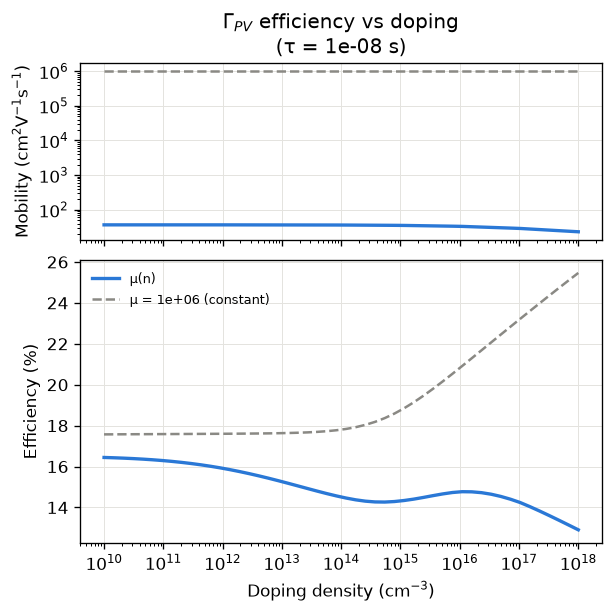

In [7]:
final_results.plot_FOM_vs_doping(mobility=mu_limiting, mu_reference=1e6, **props)
plt.show()

`FOM_vs_doping` returns the same numbers, for comparing choices on one figure:

limiting (holes)       best 16.45 % at n = 1.0e+10 cm⁻³ (mu = 36.6)
minority (electrons)   best 17.93 % at n = 1.6e+16 cm⁻³ (mu = 229)
10⁶ (infinite-μ limit) best 25.46 % at n = 1.0e+18 cm⁻³ (mu = 1e+06)


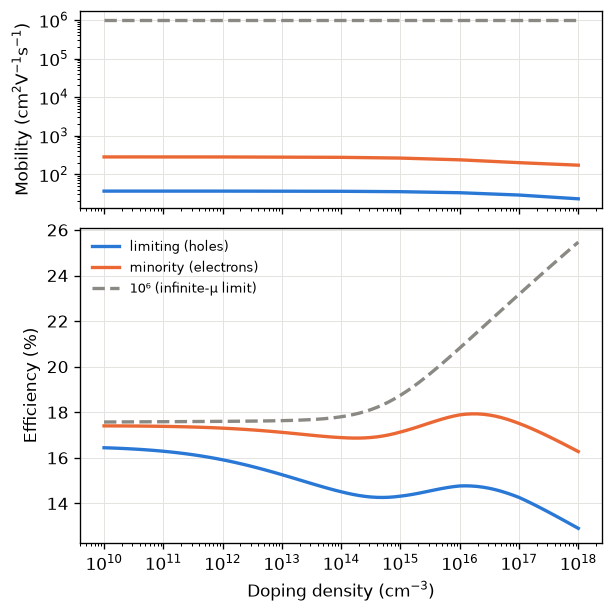

In [8]:
fig, (ax_mu, ax_eff) = plt.subplots(2, 1, figsize=(5, 5), dpi=120, sharex=True,
                                     constrained_layout=True, gridspec_kw={"height_ratios": [1, 1.6]})

for mobility, label, style in (
        (mu_limiting, "limiting (holes)", dict(color="#2a78d6")),
        (mu_minority, "minority (electrons)", dict(color="#eb6834")),
        (1e6, "10⁶ (infinite-μ limit)", dict(color="#8a8984", linestyle="--")),
):
    n, mu, eff = final_results.FOM_vs_doping(mobility=mobility, n_points=81, **props)
    ax_mu.plot(n, mu, linewidth=2, label=label, **style)
    ax_eff.plot(n, eff, linewidth=2, label=label, **style)
    best = np.argmax(eff)
    print(f"{label:22s} best {eff[best]:.2f} % at n = {n[best]:.1e} cm⁻³ (mu = {mu[best]:.3g})")

ax_mu.set(xscale="log", yscale="log", ylabel="Mobility (cm$^2$V$^{-1}$s$^{-1}$)")
ax_eff.set(xlabel="Doping density (cm$^{-3}$)", ylabel="Efficiency (%)")
ax_eff.legend(frameon=False, fontsize=8)
for ax in (ax_mu, ax_eff):
    ax.grid(True, color="#e4e3df", linewidth=0.6)
plt.show()

With $\tau$ = 10 ns, the carrier choice moves the efficiency by 1.5 - 3 percentage points, and the 10⁶ curve shows how much of the loss a hand-picked high mobility hides. Which branch of equation S2 applies depends on the injection level, which only a device simulation settles: report both when in doubt.

What this does not capture:

* The AMSET inputs marked as estimates in `settings.yaml` (ionic dielectric contribution, polar-optical frequency) set the POP-limited mobility, which dominates here. Bracket them before drawing conclusions.
* Piezoelectric scattering was left out, which slightly overestimates the mobility.
* $\Gamma_{\mathrm{PV}}$ sees one isotropic mobility; the hole anisotropy above is averaged away.
* $\tau$ is still an assumption.
* The DOS effective-mass fit above is flagged as poorly resolved on this k-mesh; see the DOS effective mass tutorial (`effmass_tutorial.ipynb`).